Universidad del Valle de Guatemala  
Departamento de Ciencias de la Computación  
CC2017 Modelación y Simulación

# 07. El simulador como servicio

Los notebooks 01 a 06 construyeron el modelo paso a paso para una cafetería tipo. En este notebook se usa la capa de servicio, que es la que consumirá el frontend del SaaS. Un usuario cualquiera ingresa los datos de su negocio y obtiene las respuestas a cada pregunta, sin tocar los parámetros técnicos del modelo.

El ejemplo es una tienda de barrio que abre de 6:00 a 21:00, la atiende una persona y vende a crédito al 30 % de sus clientes. Los datos son ilustrativos.

## 1. Datos del negocio y validación

Los datos se pasan como un diccionario, igual que llegarían desde un formulario. Antes de simular se validan.

In [1]:
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append("../src")
from business_sim import service
from business_sim.inputs import BusinessInput

tienda = {
    "name": "Tienda de barrio",
    "initial_cash": 25_000, "avg_ticket": 60, "unit_cost": 42,
    "rent": 3_500, "employees": 2, "salary": 3_800, "utilities": 800, "other_fixed": 300,
    "initial_inventory": 15_000, "spoilage_rate": 0.01,
    "loan_amount": 20_000, "annual_rate": 0.20, "loan_term": 24,
    "sales_start": 500, "sales_mature": 900, "ramp_months": 4, "seasonality": 0.10,
    "visits_per_customer": 6, "monthly_retention": 0.95,
    "servers": 1, "opening_hour": 6, "closing_hour": 21, "hourly_profile": None,
    "service_minutes": 2, "patience_minutes": 4, "max_queue": 5,
    "credit_share": 0.3, "payment_delay": 1, "monthly_default": 0.04, "default_churn": 0.5,
    "strategies": {"ad_cost": 800, "rent_cut": 0.10, "utilities_cut": 0.10},
}
try:
    BusinessInput.from_dict({**tienda, "unit_cost": 70, "closing_hour": 25})
except ValueError as error:
    print("Formulario inválido:", error)
print("Errores de la tienda:", BusinessInput.from_dict(tienda).errors())

Formulario inválido: unit_cost debe ser mayor que 0 y menor que avg_ticket. Se requiere 0 <= opening_hour < closing_hour <= 24.
Errores de la tienda: []


La validación reúne todos los errores en un solo mensaje, que el frontend puede mostrar junto al formulario. Los datos de la tienda no tienen errores.

## 2. Resumen inmediato

El resumen no usa Monte Carlo y tarda menos de un segundo. Incluye la población de clientes que se calibra a partir de las ventas esperadas.

Costos fijos = Q12,200, cuota = Q1,017.92, margen por visita = Q18
Visitas de equilibrio = 734 por mes
Meses que aguanta sin incertidumbre = 24
Población calibrada = 171, clientes iniciales = 70, boca a boca q = 0.326
Error medio de la calibración = 3.5%


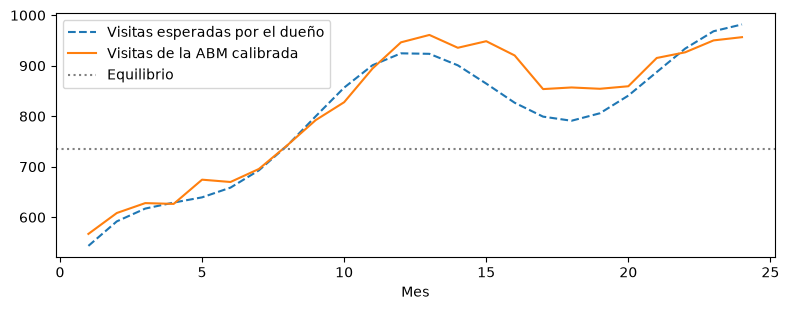

In [2]:
resumen = service.summary(tienda)
print(f"Costos fijos = Q{resumen['fixed_costs']:,.0f}, cuota = Q{resumen['loan_payment']:,.2f}, margen por visita = Q{resumen['margin_per_visit']:.0f}")
print(f"Visitas de equilibrio = {resumen['breakeven_visits']:.0f} por mes")
print(f"Meses que aguanta sin incertidumbre = {resumen['deterministic_months_survived']}")
cal = resumen["calibration"]
print(f"Población calibrada = {cal['population']}, clientes iniciales = {cal['initial_customers']}, boca a boca q = {cal['imitation']:.3f}")
print(f"Error medio de la calibración = {cal['mean_abs_pct_error']:.1%}")

meses = np.arange(1, len(resumen["expected_visits"]) + 1)
plt.figure(figsize=(8, 3.2))
plt.plot(meses, resumen["expected_visits"], "--", label="Visitas esperadas por el dueño")
plt.plot(meses, cal["abm_visits"], label="Visitas de la ABM calibrada")
plt.axhline(resumen["breakeven_visits"], color="gray", ls=":", label="Equilibrio")
plt.xlabel("Mes")
plt.legend()
plt.tight_layout()
plt.show()

La tienda necesita 734 visitas al mes para cubrir Q12 200 de costos fijos y Q1 018 de cuota con un margen de Q18 por visita. Sin incertidumbre aguanta los 24 meses. La calibración encuentra una población de 171 clientes potenciales con 70 clientes al abrir, y las visitas de la ABM se alejan 3.5 % en promedio de las que espera el dueño.

## 3. ¿Cuántos meses aguanta si las ventas son 30 % menores?

Tiempo = 11 s


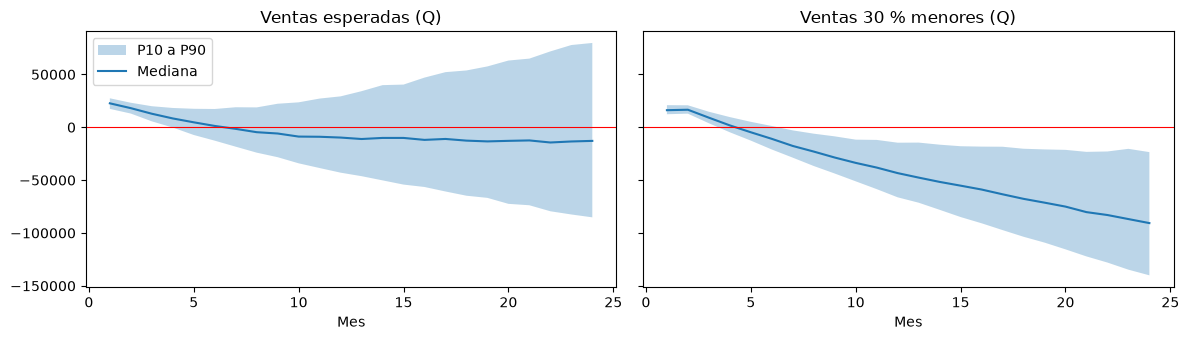

expected: probabilidad de quedarse sin caja = 0.704, pérdida en cola = 1.60%, incobrables P50 = Q6,699
reduced: probabilidad de quedarse sin caja = 0.968, pérdida en cola = 1.37%, incobrables P50 = Q4,761


Meses que aguanta  Caja mínima (Q)  \
Esperadas    Peor (P10)                    3.0         -86672.0   
             Probable (P50)                6.0         -18710.0   
             Mejor (P90)                  24.0          13250.0   
30 % menores Peor (P10)                    3.0        -140063.0   
             Probable (P50)                4.0         -90936.0   
             Mejor (P90)                   6.0         -26733.0   

                             Caja final (Q)  
Esperadas    Peor (P10)            -85212.0  
             Probable (P50)        -12891.0  
             Mejor (P90)            79754.0  
30 % menores Peor (P10)           -140063.0  
             Probable (P50)        -90654.0  
             Mejor (P90)           -23496.0

In [3]:
def rango(resultado):
    """Devuelve la tabla peor, probable y mejor de un resultado de `survival`."""
    t = pd.DataFrame(resultado["range"]).T
    t.index = ["Peor (P10)", "Probable (P50)", "Mejor (P90)"]
    t.columns = ["Meses que aguanta", "Caja mínima (Q)", "Caja final (Q)"]
    return t.round(0)


inicio = time.perf_counter()
caida = service.sales_drop(tienda, drop=0.3, n=500)
print(f"Tiempo = {time.perf_counter() - inicio:.0f} s")

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for eje, clave, titulo in zip(ejes, ["expected", "reduced"], ["Ventas esperadas", "Ventas 30 % menores"]):
    fan = caida[clave]["cash_fan"]
    eje.fill_between(fan["month"], fan["p10"], fan["p90"], alpha=0.3, label="P10 a P90")
    eje.plot(fan["month"], fan["p50"], label="Mediana")
    eje.axhline(0, color="red", lw=0.8)
    eje.set_title(f"{titulo} (Q)")
    eje.set_xlabel("Mes")
ejes[0].legend()
plt.tight_layout()
plt.show()
for clave in ["expected", "reduced"]:
    r = caida[clave]
    print(f"{clave}: probabilidad de quedarse sin caja = {r['probability_out_of_cash']:.3f}, pérdida en cola = {r['mean_queue_loss']:.2%}, incobrables P50 = Q{r['bad_debt_median']:,.0f}")
pd.concat({"Esperadas": rango(caida["expected"]), "30 % menores": rango(caida["reduced"])})

El reporte de 1 000 escenarios tarda 11 s, aunque el tiempo varía con cada ejecución. Con las ventas esperadas la tienda se queda sin caja en el 70.4 % de los escenarios, aunque sin incertidumbre aguantaba los 24 meses. El escenario probable aguanta 6 meses y el mejor llega al mes 24 con Q79 754. Con ventas 30 % menores el riesgo sube a 96.8 % y el escenario probable aguanta 4 meses. La diferencia con el resumen se debe al margen de Q18 por visita, que deja poco espacio a variaciones en ventas y costos.

## 4. ¿Cuántos clientes se necesita retener cada mes?

In [4]:
ret = service.retention(tienda, n=300)
print(f"Retención declarada = {ret['expected_retention']}, riesgo objetivo = {ret['target_risk']}, retención mínima = {ret['min_retention']}")
pd.DataFrame(ret["rows"]).set_index("retention").round(3)

Retención declarada = 0.95, riesgo objetivo = 0.1, retención mínima = None


,probability_survive,median_months,median_active_end,retained_customers_per_month
retention,,,,
0.80,0.007,4.0,52.5,42.00
0.84,0.040,4.0,80.0,67.20
0.88,0.080,5.0,105.0,92.40
0.90,0.133,5.0,115.0,103.50
0.92,0.160,5.0,128.0,117.76
0.94,0.250,5.0,139.0,130.66
0.96,0.303,6.0,148.0,142.08
0.98,0.387,6.0,158.0,154.84


Ninguna retención evaluada baja el riesgo a 10 %, por lo que la retención mínima es None. Con 98 % de retención la probabilidad de llegar al mes 24 es de 38.7 %. Para esta tienda retener clientes no basta y el problema está en el margen.

## 5. ¿Qué estrategia conviene?

Las magnitudes de publicidad y recortes se ajustaron a la escala de la tienda en el diccionario de datos.

In [5]:
est = service.strategies(tienda, n=300)
for nombre, desc in est["descriptions"].items():
    print(f"{nombre}: {desc}")
tablas = {}
for esc in est["scenarios"]:
    print(f"Cambio en ventas {esc['sales_change']:+.0%}: recomendación = {esc['recommendation']}")
    tablas[f"{esc['sales_change']:+.0%}"] = pd.DataFrame(esc["rows"]).set_index("strategy")[["probability_survive", "final_cash_p50", "mean_queue_loss"]]
pd.concat(tablas).round(3)

Sin cambios: Parámetros base.
Publicidad: Q800 al mes en publicidad y coeficiente de innovación p multiplicado por 4.
Lealtad: Abandono promedio 25% menor a cambio de 5% de descuento en el ticket.
Contratar: 1 empleado(s) más que atienden en mostrador.
Recortar fijos: Alquiler 10% menor y servicios 10% menores.
Cambio en ventas +0%: recomendación = Recortar fijos
Cambio en ventas -30%: recomendación = Recortar fijos


probability_survive  final_cash_p50  mean_queue_loss
     strategy                                                            
+0%  Sin cambios                   0.273      -15230.458            0.016
     Publicidad                    0.213      -27221.426            0.016
     Lealtad                       0.083      -57177.453            0.017
     Contratar                     0.040      -94662.067            0.000
     Recortar fijos                0.347       -4910.458            0.016
-30% Sin cambios                   0.037      -91746.587            0.014
     Publicidad                    0.020     -108329.058            0.014
     Lealtad                       0.010     -121963.875            0.014
     Contratar                     0.000     -177434.965            0.000
     Recortar fijos                0.053      -81426.587            0.014

En ambos escenarios se recomienda recortar fijos, que sube la probabilidad de 27.3 % a 34.7 % con las ventas esperadas. Contratar baja la pérdida en cola a 0 % pero la probabilidad cae a 4.0 %, y la lealtad cae a 8.3 % porque el descuento reduce un margen ya estrecho.

## 6. ¿Qué datos pesan más?

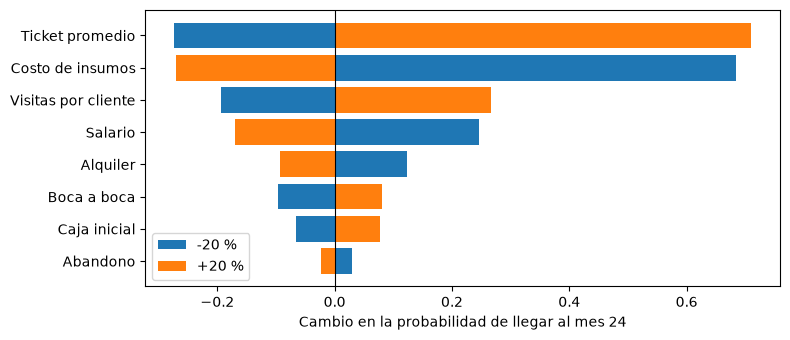

Probabilidad base = 0.273


,low,high,range
label,,,
Ticket promedio,0.000,0.983,0.983
Costo de insumos,0.957,0.003,0.953
Visitas por cliente,0.080,0.540,0.460
Salario,0.520,0.103,0.417
Alquiler,0.397,0.180,0.217
Boca a boca,0.177,0.353,0.177
Caja inicial,0.207,0.350,0.143
Abandono,0.303,0.250,0.053


In [6]:
sens = service.sensitivity(tienda, n=300)
tabla = pd.DataFrame(sens["rows"]).set_index("label")
plt.figure(figsize=(8, 3.5))
plt.barh(tabla.index[::-1], tabla["low"][::-1] - sens["base_probability"], label="-20 %")
plt.barh(tabla.index[::-1], tabla["high"][::-1] - sens["base_probability"], label="+20 %")
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Cambio en la probabilidad de llegar al mes 24")
plt.legend()
plt.tight_layout()
plt.show()
print(f"Probabilidad base = {sens['base_probability']:.3f}")
tabla[["low", "high", "range"]].round(3)

El ticket promedio y el costo de insumos dominan. Con 20 % más de ticket o 20 % menos de costo la probabilidad sube a 98.3 % y 95.7 %. El abandono es el dato que menos pesa, con un rango de 0.053.

## 7. ¿Conviene vender a crédito?

In [7]:
cred = service.credit(tienda, n=300)
print(f"Caso hipotético = {cred['what_if']}, fracción a crédito = {cred['credit_share']}")
print(f"Solo contado = {cred['cash_only']['probability_survive']:.3f}, con crédito = {cred['with_credit']['probability_survive']:.3f}")
print(f"Incobrables P50 = Q{cred['with_credit']['bad_debt_p50']:,.0f}, P90 = Q{cred['with_credit']['bad_debt_p90']:,.0f}")
print(f"Mora máxima tolerable (caída de hasta {cred['max_drop']:.0%}) = {cred['max_tolerable_default']}")
pd.concat({
    "Mora mensual": pd.DataFrame(cred["default_curve"]).set_index("monthly_default"),
    "Plazo (meses)": pd.DataFrame(cred["delay_curve"]).set_index("payment_delay"),
}).round(3)

Caso hipotético = False, fracción a crédito = 0.3
Solo contado = 0.490, con crédito = 0.273
Incobrables P50 = Q6,952, P90 = Q10,533
Mora máxima tolerable (caída de hasta 5%) = None


probability_survive
Mora mensual  0.00                0.303
              0.02                0.307
              0.05                0.270
              0.10                0.257
              0.15                0.233
              0.20                0.220
Plazo (meses) 1.00                0.273
              2.00                0.110
              3.00                0.013

La tienda declara 30 % de ventas a crédito, por lo que el resultado no es hipotético. Vender a crédito baja la probabilidad de llegar al mes 24 de 49.0 % a 27.3 %. Ninguna mora cumple la tolerancia de 5 % porque solo el retraso del cobro ya baja la probabilidad a 30.3 %. El plazo pesa más que la mora, con 11.0 % a 2 meses y 1.3 % a 3 meses.

## 8. Las mismas respuestas desde la API

El frontend no llamará a Python directamente, sino a la API REST. Las preguntas largas se piden como trabajos en segundo plano y se consulta su estado hasta que terminan. Se compara el resultado con el del servicio usando la misma semilla.

In [8]:
import warnings

warnings.filterwarnings("ignore", message="Using .httpx. with .starlette.testclient.")
from fastapi.testclient import TestClient

from business_sim.api import app

cliente = TestClient(app)
trabajo = cliente.post("/jobs/survival", json={"business": tienda, "options": {"n": 100}}).json()
print("Respuesta al crear el trabajo:", trabajo)
while (estado := cliente.get(f"/jobs/{trabajo['job_id']}").json())["status"] in ("queued", "running"):
    time.sleep(0.5)
print("Estado final:", estado["status"])
directo = service.survival(tienda, n=100)
print(f"Probabilidad por la API = {estado['result']['probability_survive']:.3f}, por el servicio = {directo['probability_survive']:.3f}")

Respuesta al crear el trabajo: {'job_id': '7d2d40b59b89496480df31f8424d4d2c', 'question': 'survival', 'status': 'queued'}


Estado final: done


Probabilidad por la API = 0.210, por el servicio = 0.210


El trabajo termina en estado done y la probabilidad por la API es igual a la del servicio, 0.210, porque ambos usan la misma semilla.

## Conclusión

Con la capa de servicio cualquier negocio obtiene las mismas respuestas que se construyeron para la cafetería, a partir de datos que el dueño conoce. Para esta tienda el resultado más útil es que el margen por visita, y no la clientela, define su supervivencia, y que vender a crédito con plazos largos la pone en riesgo.